In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src'))
from train_model import FEATURES, load_and_prepare

data_path = ROOT / 'data' / 'sl_al_2020_sample.csv'
X, y, frame = load_and_prepare(data_path)
X = X.fillna('Unknown').astype(str)
print('Rows:', len(frame))
print('Features:', FEATURES)
frame.head()

Rows: 80000
Features: ['stream', 'syllabus', 'sub1', 'sub1_r', 'sub2', 'sub2_r', 'sub3', 'sub3_r']


,stream,syllabus,sub1,sub1_r,sub2,sub2_r,sub3,sub3_r,ge_r
0,<NA>,new,ECONOMICS,S,BUSINESS STUDIES,C,ACCOUNTING,F,F
1,<NA>,new,ECONOMICS,F,BUSINESS STUDIES,F,ACCOUNTING,F,F
2,ARTS,new,GEOGRAPHY,B,CHRISTIAN CIVILIZATION,B,TAMIL,B,S
3,ARTS,new,POLITICAL SCIENCE,S,COMMUNICATION & MEDIA STUDIES,C,SINHALA,B,S
4,BIOSYSTEMS TECHNOLOGY,new,INFORMATION & COMMUNICATION TECHNOLOGY,S,BIO SYSTEMS TECHNOLOGY,S,SCIENCE FOR TECHNOLOGY,S,F


Data types:
stream      string[python]
syllabus    string[python]
sub1        string[python]
sub1_r      string[python]
sub2        string[python]
sub2_r      string[python]
sub3        string[python]
sub3_r      string[python]
ge_r        string[python]
dtype: object

Missing values:
stream      35752
syllabus        0
sub1            0
sub1_r          0
sub2            0
sub2_r          0
sub3            0
sub3_r          0
ge_r            0
dtype: int64

Target counts:
ge_r
Non-pass    45021
Pass        34979
Name: count, dtype: int64


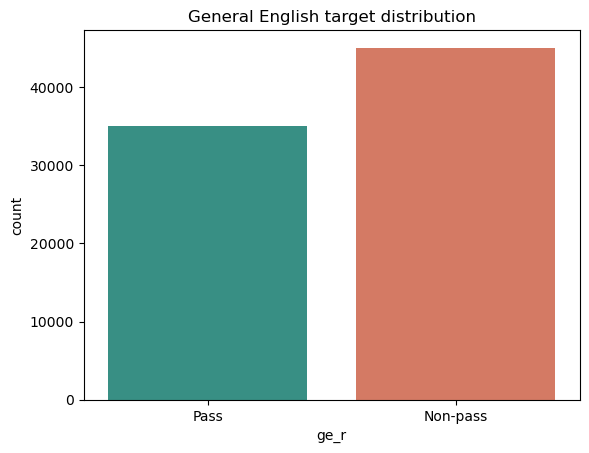

In [2]:
print('Data types:')
print(frame.dtypes)
print()
print('Missing values:')
print(frame[FEATURES + ['ge_r']].isna().sum())
print()
print('Target counts:')
print(y.map({0: 'Non-pass', 1: 'Pass'}).value_counts())

sns.countplot(x=y.map({0: 'Non-pass', 1: 'Pass'}), order=['Pass', 'Non-pass'], palette=['#2a9d8f', '#e76f51'])
plt.title('General English target distribution')
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(64000, 8) (16000, 8)


In [4]:
from train_model import tune_models, make_catboost, fit_and_score

rf_search, xgb_search = tune_models(X_train, y_train)
models = {
    'Random Forest': rf_search.best_estimator_,
    'XGBoost': xgb_search.best_estimator_,
    'CatBoost': make_catboost(),
}
metrics = fit_and_score(models, X_train, X_test, y_train, y_test)
metrics_df = pd.DataFrame(metrics).sort_values('f1_macro', ascending=False)
metrics_df

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
1,XGBoost,0.749625,0.746135,0.748392,0.746901,0.832371
2,CatBoost,0.746625,0.752229,0.755018,0.746428,0.831902
0,Random Forest,0.745250,0.745970,0.749876,0.744412,0.825270


In [5]:
print('Tuned Random Forest parameters:')
print(rf_search.best_params_)
print()
print('Tuned XGBoost parameters:')
print(xgb_search.best_params_)

Tuned Random Forest parameters:
{'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 18}

Tuned XGBoost parameters:
{'model__subsample': 0.75, 'model__n_estimators': 280, 'model__max_depth': 7, 'model__learning_rate': 0.04, 'model__colsample_bytree': 0.75}


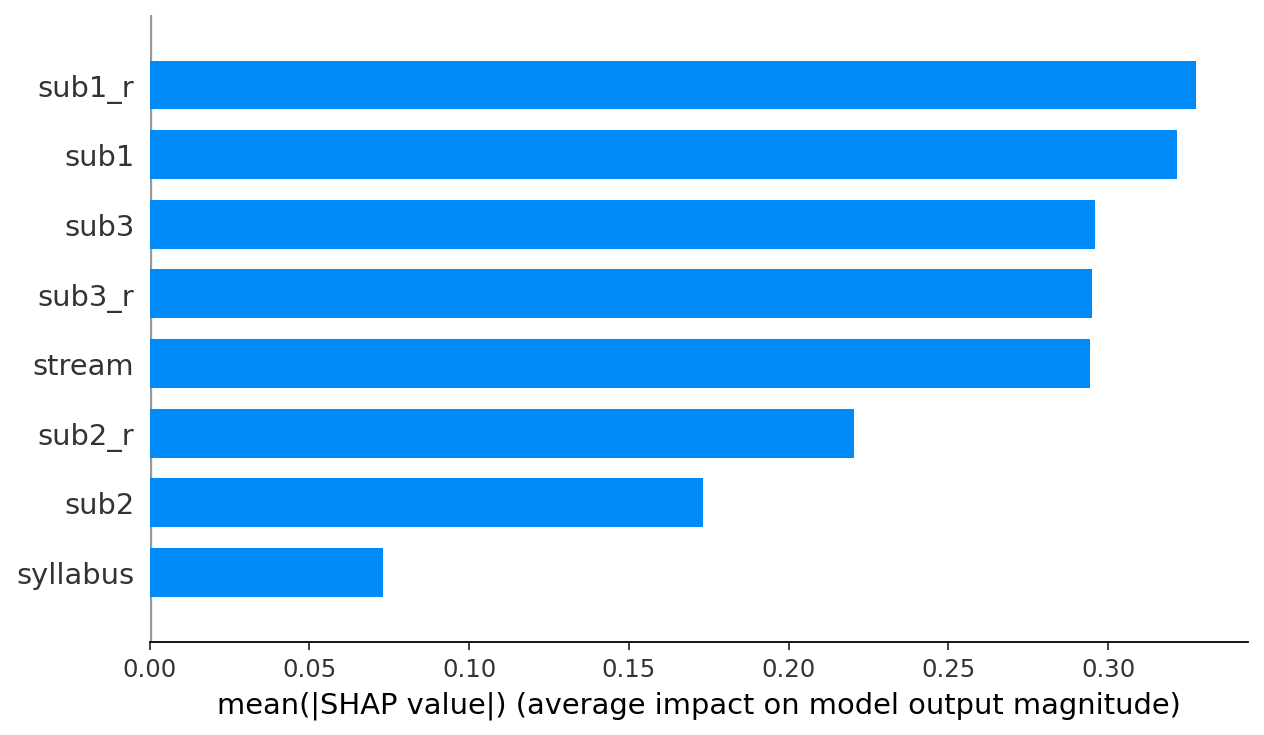

In [6]:
from train_model import explain_with_shap, explain_with_lime

explain_with_shap(models['CatBoost'], X_test)
explain_with_lime(models['CatBoost'], X_train, X_test)
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs' / 'shap_summary.png')))

In [7]:
best_name = metrics_df.iloc[0]['model']
best_model = models[best_name]
one_row = X_test.iloc[[0]]
prediction = int(best_model.predict(one_row)[0])
probability = float(best_model.predict_proba(one_row)[0, 1])
print('Best model:', best_name)
print('Predicted target:', 'Pass' if prediction == 1 else 'Non-pass')
print('Pass probability:', round(probability, 3))
one_row

Best model: XGBoost
Predicted target: Non-pass
Pass probability: 0.216


,stream,syllabus,sub1,sub1_r,sub2,sub2_r,sub3,sub3_r
32349,Unknown,new,GEOGRAPHY,F,HISTORY OF SRI LANKA & EUROPE,S,ISLAMIC CIVILIZATION,C
